In [3]:
# importing all libraries 
import pathlib 
import numpy as np
import matplotlib.pyplot as plt
import tifffile 

In [4]:
# Connect to dropbox database 
from pathlib import Path
folder = Path("C:\\Users\\issyh\\Downloads\\sensitivity_chunk_IC_768")
folder = folder / "sensitivity_chunk_IC_768"
folder.exists()

True

In [5]:
# Check for paths of files in folder and length of files to be 768 (items)
files = sorted(folder.glob('*.tif'))
print(len(files))
print(files[:2])

768
[WindowsPath('C:/Users/issyh/Downloads/sensitivity_chunk_IC_768/sensitivity_chunk_IC_768/cst_slab_7680000.tif'), WindowsPath('C:/Users/issyh/Downloads/sensitivity_chunk_IC_768/sensitivity_chunk_IC_768/cst_slab_7680001.tif')]


In [6]:
# Test tiffile.imread on first file and check again for it shape and dtype
img = tifffile.imread(files[0])
print(img.shape, img.dtype)

(767, 768) uint8


In [7]:
# Read all the slices and stack them into a 3D array
slices = []
for f in files:
    img = tifffile.imread(f)
    slices.append(img)

# Important: stacked slices into a 3D array
volume = np.stack(slices)

print(volume.shape, volume.dtype)

(768, 767, 768) uint8


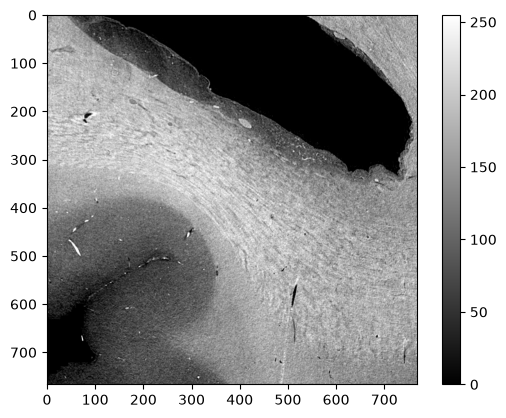

In [ ]:
# Practice extracting a slice from the 3D array and visualizing it

# Extract an arbitrary slice from 3D array
slice_index = 50  # Example index
slice_data = volume[slice_index, :, :]  # Extracting a slice along the z-axis

# Takes above array and illustrates each pixel according to its brightness (0-255) 
# Check if similiar to a brain slice 
plt.imshow(slice_data, cmap='gray') # cmap renders it in grayscale rather than rainbow colormap
plt.colorbar() # adds scale on to side, mapping pixel brightness back to 0-255 numbers
plt.show()

In [16]:
volume.shape

(768, 767, 768)

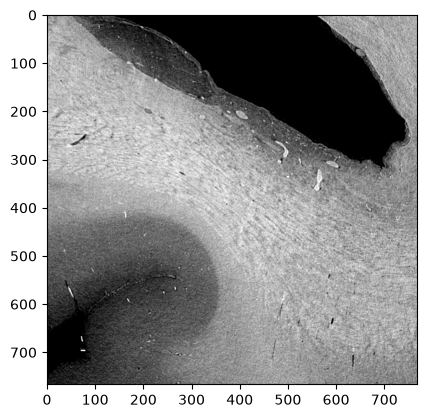

In [32]:
plt.imshow(volume[0, :, :], cmap='gray') # visualize a slice along the z-axis

In [ ]:
# Computing structure tensors of 3D brain volume sample data
import numpy as np
from structure_tensor import eig_special_3d, structure_tensor_3d

# First-round starting parameters
sigma = 1.5
rho = 5.5

# practice round on smaller vol due to lack of RAM
volume_small = volume[:256, :256, :256]

# Swapping from 0-225 integers to any number, including negative and fractional 
# to accomodate gradient calculations
volume_float = volume_small.astype(np.float32)

S = structure_tensor_3d(volume_float, sigma, rho)
val, vec = eig_special_3d(S)

print(np.isnan(vec).sum())
print(np.isnan(vec).sum() / vec.size)

1769207
0.03515098492304484


In [15]:
print(vec.shape)

(3, 256, 256, 256)


In [33]:
# Extract slice 50
vec_50 = vec[:, 50, :, :]

# Transpose to XYZ
vec_50 = vec_50.transpose(1, 2, 0)
vec_50.shape

(256, 256, 3)

C:\Users\issyh\AppData\Local\Temp\ipykernel_11104\2995537069.py:3: RuntimeWarning: invalid value encountered in cast
  vec_50 = vec_50.astype(np.uint8)


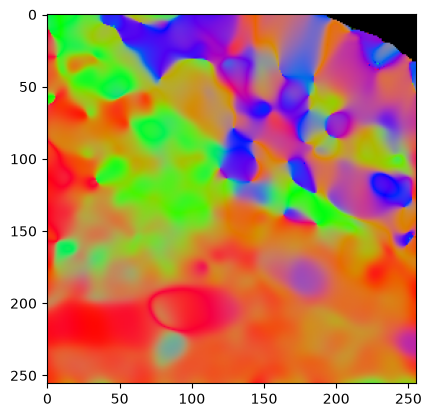

In [34]:
vec_50 = np.abs(vec_50)
vec_50 = vec_50 * 255
vec_50 = vec_50.astype(np.uint8)
plt.imshow(vec_50)


(256, 256, 256)


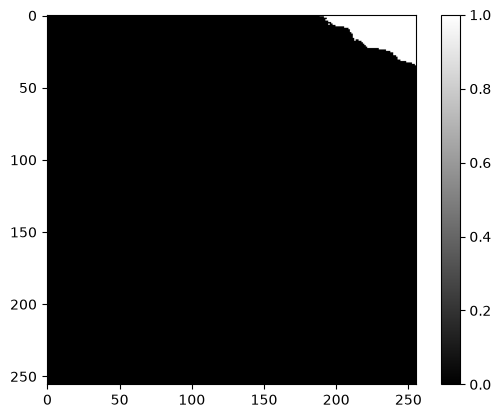

In [36]:
import matplotlib.pyplot as plt

nan_mask = np.isnan(vec).any(axis=0)
print(nan_mask.shape)

middle = nan_mask.shape[0] // 2
plt.imshow(nan_mask[middle], cmap='gray')
plt.colorbar()
plt.show()

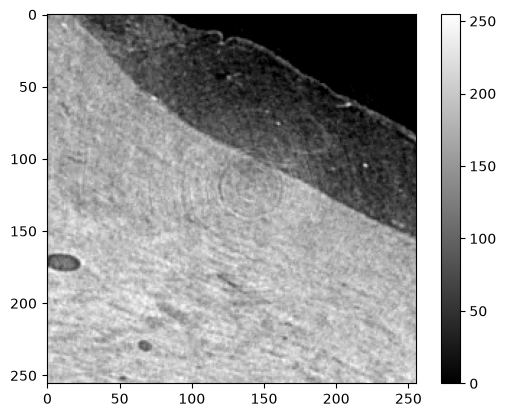

In [37]:
plt.imshow(volume_small[middle], cmap='gray')
plt.colorbar()
plt.show()

(3, 256, 256, 256)


C:\Users\issyh\AppData\Local\Temp\ipykernel_11104\2307268246.py:17: RuntimeWarning: invalid value encountered in divide
  FA = np.sqrt(1.5 * (numerator / denominator))


(256, 256, 256)
0.0 1.1338934


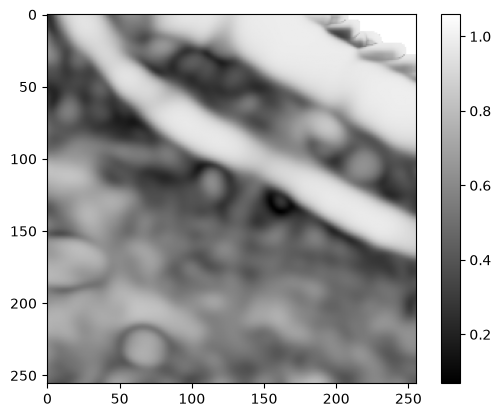

In [ ]:
# Check shape of val 
print(val.shape) # expect (3, 256, 256, 256) 

import numpy as np
import matplotlib.pyplot as plt

# Full FA formula
# Mean eigenvalue at every voxel
lambda_mean = val.mean(axis=0)

# Numerator: squared deviation of each eigenvalue from the mean, summed
numerator = (val[0] - lambda_mean)**2 + (val[1] - lambda_mean)**2 + (val[2] - lambda_mean)**2

# Denominator: sum of squared eigenvalues (normalises for overall magnitude)
denominator = val[0]**2 + val[1]**2 + val[2]**2

FA = np.sqrt(1.5 * (numerator / denominator))

print(FA.shape)
print(np.nanmin(FA), np.nanmax(FA))

middle = FA.shape[0] // 2
plt.imshow(FA[middle], cmap='gray')
plt.colorbar()
plt.show()
